# Proyecto 01 · Retail Intelligence · A3: Devoluciones, CRM, Churn e Ingreso en Riesgo

**Autores:** Daniel, Andrés y Samuel (Grupo 3)  
**Materia:** Tópicos Especiales para la Gestión de Datos · UCAB  
**Profesor:** Armen Djenanian  

---

### Preguntas de Investigación y Objetivos
1. **A3.1:** ¿Existen productos con tasas anómalas de devolución por encima del estándar de su categoría, o el volumen de devoluciones responde a un efecto base del catálogo? ¿Son los clientes con múltiples devoluciones comportamientos anómalos o responden a una distribución binomial de compra? ¿Cómo evoluciona la tasa trimestral y cómo se distribuyen los motivos?
2. **A3.2:** ¿Impactan las quejas no resueltas de CRM la frecuencia posterior de compra del cliente, o la evidencia empírica descarta un efecto causal directo frente a quejas resueltas? ¿Existe un cruce significativo entre quejas no resueltas y riesgo de churn?
3. **A3.3:** ¿Bajo el enfoque relativo de churn personalizado ($C+B$, percentil 85 = 127 días), cuántos clientes y qué valor en riesgo acumula la cartera?
4. **A3.4:** ¿Cuál es la pérdida esperada de ingreso proyectada a 6 meses bajo supuestos conservadores y qué segmentos concentran la mayor exposición?


## 1. Carga y conexión

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sqlalchemy import create_engine

# Buscar .env en el directorio actual o en el padre
for ruta in (Path.cwd() / '.env', Path.cwd().parent / '.env'):
    if ruta.exists():
        load_dotenv(ruta)
        break

DATABASE_URL = os.getenv('DATABASE_URL')
if not DATABASE_URL:
    raise SystemExit('Falta DATABASE_URL. Copia .env en la raiz del repo o define la variable de entorno.')

engine = create_engine(DATABASE_URL, pool_pre_ping=True)

transacciones = pd.read_sql('SELECT * FROM clean.transacciones', engine)
devoluciones  = pd.read_sql('SELECT * FROM clean.devoluciones', engine)
clientes      = pd.read_sql('SELECT * FROM clean.clientes', engine)
interacciones = pd.read_sql('SELECT * FROM clean.interacciones_crm', engine)
productos     = pd.read_sql('SELECT * FROM clean.productos', engine)
dim_fecha     = pd.read_sql('SELECT * FROM clean.dim_fecha', engine)

# Convertir columnas de fecha a datetime
for df, cols in [
    (transacciones, ['fecha', 'fecha_devolucion']),
    (devoluciones, ['fecha_devolucion']),
    (clientes, ['fecha_registro', 'primera_compra', 'ultima_compra', 'fecha_alta_efectiva']),
    (interacciones, ['fecha']),
]:
    for c in cols:
        df[c] = pd.to_datetime(df[c], errors='coerce')

print(f'transacciones: {len(transacciones):,} filas')
print(f'devoluciones:  {len(devoluciones):,} filas')
print(f'clientes:      {len(clientes):,} filas')
print(f'interacciones: {len(interacciones):,} filas')
print(f'productos:     {len(productos):,} filas')
print(f'dim_fecha:     {len(dim_fecha):,} filas')

transacciones: 50,000 filas
devoluciones:  6,724 filas
clientes:      8,000 filas
interacciones: 4,684 filas
productos:     318 filas
dim_fecha:     731 filas


## 2. Parámetros globales

In [2]:
# Ventana del caso y constantes de análisis
FECHA_CORTE = pd.Timestamp('2024-12-31')   # fin del caso (24 meses)
INICIO = pd.Timestamp('2023-01-01')        # inicio del caso
MESES_HISTORICO = 12                       # ventana para el promedio de gasto reciente
MESES_PROYECCION = 6                       # horizonte de proyeccion de ingreso
FACTORES_SENSIBILIDAD = [0.75, 1.0, 1.5, 2.0]   # multiples del umbral de churn
FACTORES_SENSIBILIDAD_W = [0.5, 1.0, 1.5]       # multiples de la ventana CRM

print(f'Fecha de corte: {FECHA_CORTE.date()}')
print(f'Horizonte de proyeccion: {MESES_PROYECCION} meses')
print(f'Ventana historica para gasto: {MESES_HISTORICO} meses activos')

Fecha de corte: 2024-12-31
Horizonte de proyeccion: 6 meses
Ventana historica para gasto: 12 meses activos


## 3. Métricas base (funciones reutilizables)

In [3]:
def pct(parte, total):
    '''Porcentaje seguro (evita division por cero).'''
    return 100.0 * parte / total if total else 0.0

# Definiciones del contrato de metricas (ver README / documento del equipo):
#   ingreso_neto        = monto_neto
#   ingreso_neto_final  = monto_neto - monto_devuelto
#   margen_bruto        = monto_neto - costo_total
#   margen_neto_devol   = 0 si hubo devolucion (supuesto: anula la venta y su margen)
#   tasa_devolucion     = transacciones devueltas / transacciones elegibles
#   ingreso en riesgo   = promedio mensual de los ultimos 12 meses activos x 6

## 4. Sanity check de totales (deben coincidir con A1)

In [4]:
ingreso_total = transacciones['monto_neto'].sum()
margen_total = transacciones['margen_bruto'].sum()
monto_dev_total = transacciones['monto_devuelto'].sum()

print(f'Ingreso neto total:  {ingreso_total:,.2f}  (esperado 17,392,987.48)')
print(f'Margen bruto total:  {margen_total:,.2f}  (esperado 4,310,329.05)')
print(f'Monto devuelto total: {monto_dev_total:,.2f}')
print(f'Ticket promedio:     {transacciones["monto_neto"].mean():,.2f}')

Ingreso neto total:  17,392,987.48  (esperado 17,392,987.48)
Margen bruto total:  4,310,329.05  (esperado 4,310,329.05)
Monto devuelto total: 2,534,466.22
Ticket promedio:     347.86


## 5. Reconciliación de devoluciones (doble fuente)

Fuente canónica: `clean.devoluciones`. Comparamos contra los campos `devuelto` / `monto_devuelto` de `clean.transacciones` para detectar inconsistencias antes de usar los datos.

In [5]:
ids_tx = set(transacciones['transaccion_id'])
ids_dev = set(devoluciones['transaccion_id'])

# 1) Devoluciones sin transaccion asociada (huerfanas)
solo_dev = devoluciones[~devoluciones['transaccion_id'].isin(ids_tx)]

# 2) Transacciones marcadas devuelto=1 sin fila en devoluciones
flag_sin_dev = transacciones.loc[transacciones['devuelto'] == 1, 'transaccion_id']
flag_sin_dev = flag_sin_dev[~flag_sin_dev.isin(ids_dev)]

# 3) Comparacion de montos por transaccion
dev_agg = devoluciones.groupby('transaccion_id')['monto_devuelto'].sum().rename('monto_dev_tabla').reset_index()
comp = transacciones[['transaccion_id', 'monto_devuelto', 'monto_neto']].merge(
    dev_agg, on='transaccion_id', how='left'
)
comp['monto_dev_tabla'] = comp['monto_dev_tabla'].fillna(0)
comp['dif_monto'] = (comp['monto_dev_tabla'] - comp['monto_devuelto']).round(2)
dif_monto = comp[comp['dif_monto'].abs() > 0.01]

# 4) Devoluciones parciales vs totales
con_dev = comp[comp['monto_dev_tabla'] > 0].copy()
con_dev['es_total'] = con_dev['monto_dev_tabla'] >= con_dev['monto_neto'] - 0.01

print(f'Devoluciones sin transaccion (huerfanas): {len(solo_dev)}')
print(f'Transacciones devuelto=1 sin fila en devoluciones: {len(flag_sin_dev)}')
print(f'Filas con diferencia de monto > 0.01: {len(dif_monto)}')
print(f'Devoluciones totales (monto == neto): {int(con_dev["es_total"].sum())} de {len(con_dev)}')
print(f'Devoluciones parciales (monto < neto): {int((~con_dev["es_total"]).sum())} de {len(con_dev)}')

Devoluciones sin transaccion (huerfanas): 0
Transacciones devuelto=1 sin fila en devoluciones: 0
Filas con diferencia de monto > 0.01: 0
Devoluciones totales (monto == neto): 6724 de 6724
Devoluciones parciales (monto < neto): 0 de 6724


## 6. Intervalo mediano entre compras

Se usa como ventana de referencia (`W`) para el análisis de CRM y como umbral base de inactividad (churn).

In [6]:
t = transacciones.sort_values(['cliente_id', 'fecha']).copy()
t['fecha_prev'] = t.groupby('cliente_id')['fecha'].shift(1)
t['dias_entre_compras'] = (t['fecha'] - t['fecha_prev']).dt.days
dias = t['dias_entre_compras'].dropna()

INTERVALO_MEDIANO = float(dias.median())
print(f'Intervalo mediano entre compras (global): {INTERVALO_MEDIANO:.1f} dias')
print(f'Compras consecutivas consideradas: {len(dias):,}')

# Por segmento (contexto; el umbral base sigue siendo el global)
# transacciones ya trae 'segmento' desnormalizado, no hace falta merge
print('\nMediana por segmento (dias):')
print(t.groupby('segmento')['dias_entre_compras'].median().round(1).to_string())

Intervalo mediano entre compras (global): 40.0 dias
Compras consecutivas consideradas: 42,392

Mediana por segmento (dias):
segmento
Esporádico    138.0
Frecuente      43.0
Inactivo        NaN
Nuevo         226.5
Premium        25.0


## 7. A3.1 — Devoluciones

In [7]:
# Tasa global y proporcion de ingreso perdido
n_tx = transacciones['transaccion_id'].nunique()
n_dev = devoluciones['transaccion_id'].nunique()

tx = transacciones.copy()
tx['es_devolucion'] = tx['transaccion_id'].isin(set(devoluciones['transaccion_id']))

elegibles = tx[tx['ventana_devol_incompleta'] == 0]
n_tx_eleg = elegibles['transaccion_id'].nunique()
n_dev_eleg = int(elegibles['es_devolucion'].sum())

tasa_global = pct(n_dev, n_tx)
tasa_elegible = pct(n_dev_eleg, n_tx_eleg)
ingreso_perdido_pct = pct(devoluciones['monto_devuelto'].sum(), transacciones['monto_neto'].sum())

print(f'Transacciones totales: {n_tx:,}')
print(f'Transacciones devueltas: {n_dev:,}')
print(f'Tasa de devolucion (todas): {tasa_global:.2f}%')
print(f'Tasa de devolucion (excluye ventana incompleta): {tasa_elegible:.2f}%')
print(f'Ingreso devuelto / ingreso neto: {ingreso_perdido_pct:.2f}%')

Transacciones totales: 50,000


Transacciones devueltas: 6,724
Tasa de devolucion (todas): 13.45%
Tasa de devolucion (excluye ventana incompleta): 13.45%
Ingreso devuelto / ingreso neto: 14.57%


In [8]:
# Desglose por categoria (tasa y monto)
by_cat = tx.groupby('categoria').agg(
    transacciones=('transaccion_id', 'count'),
    devoluciones=('es_devolucion', 'sum'),
    monto_neto=('monto_neto', 'sum'),
    monto_devuelto=('monto_devuelto', 'sum'),
).reset_index()
by_cat['tasa_%'] = (100 * by_cat['devoluciones'] / by_cat['transacciones']).round(2)
by_cat['%_monto_devuelto'] = (100 * by_cat['monto_devuelto'] / by_cat['monto_devuelto'].sum()).round(2)
by_cat = by_cat.sort_values('tasa_%', ascending=False)

# Categorias anormalmente altas (> 1.5x la mediana de tasa)
mediana_tasa = by_cat['tasa_%'].median()
anomalas = by_cat[by_cat['tasa_%'] > 1.5 * mediana_tasa]

print('Tasa de devolucion por categoria:')
print(by_cat.to_string(index=False))
print(f'\nMediana de tasa por categoria: {mediana_tasa:.2f}%')
print(f'Categorias con tasa > 1.5x mediana ({1.5 * mediana_tasa:.2f}%):')
print(anomalas[['categoria', 'tasa_%']].to_string(index=False))

Tasa de devolucion por categoria:
          categoria  transacciones  devoluciones  monto_neto  monto_devuelto  tasa_%  %_monto_devuelto
     Ropa_y_Calzado           8311          1810  1513396.68       320971.60   21.78             12.66
        Electrónica           8419          1486  7662506.08      1398217.45   17.65             55.17
           Deportes           8311           887  2592709.06       271614.86   10.67             10.72
    Belleza_y_Salud           8287           878   748631.63        79804.90   10.59              3.15
Alimentos_y_Bebidas           8317           845   409879.05        42909.88   10.16              1.69
       Hogar_y_Deco           8355           818  4465864.98       420947.53    9.79             16.61

Mediana de tasa por categoria: 10.63%
Categorias con tasa > 1.5x mediana (15.94%):
     categoria  tasa_%
Ropa_y_Calzado   21.78
   Electrónica   17.65


In [9]:
# A3.1 Devoluciones por segmento y productos con tasa de devolución anómala (C11)
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint

MIN_TX_PRODUCTO = 30

# 1. Tasa por segmento
by_seg = tx.groupby('segmento').agg(
    transacciones=('transaccion_id', 'count'),
    devoluciones=('es_devolucion', 'sum'),
    monto_devuelto=('monto_devuelto', 'sum'),
).reset_index()
by_seg['tasa_%'] = (100 * by_seg['devoluciones'] / by_seg['transacciones']).round(2)
by_seg = by_seg.sort_values('tasa_%', ascending=False)
print("TASA DE DEVOLUCIÓN POR SEGMENTO:")
display(by_seg)

# 2. Tasa por producto vs. el resto de su categoría (excluye al propio producto de la referencia)
prod_agg = tx.groupby(['producto_id', 'categoria']).agg(
    n_tx=('transaccion_id', 'count'),
    n_dev=('es_devolucion', 'sum'),
    monto_devuelto=('monto_devuelto', 'sum')
).reset_index()
prod_agg = prod_agg.merge(productos[['producto_id', 'nombre']], on='producto_id', how='left')

cat_tot = tx.groupby('categoria').agg(n_tx_cat=('transaccion_id', 'count'), n_dev_cat=('es_devolucion', 'sum'))
prod_30 = prod_agg[prod_agg['n_tx'] >= MIN_TX_PRODUCTO].merge(cat_tot, left_on='categoria', right_index=True)
prod_30['tasa_prod_%'] = prod_30['n_dev'] / prod_30['n_tx'] * 100
prod_30['tasa_resto_cat_%'] = (prod_30['n_dev_cat'] - prod_30['n_dev']) / (prod_30['n_tx_cat'] - prod_30['n_tx']) * 100
ic_w = [proportion_confint(k, n, alpha=0.05, method='wilson') for k, n in zip(prod_30['n_dev'], prod_30['n_tx'])]
prod_30['ic95_inf_%'] = [l * 100 for l, _ in ic_w]
prod_30['ic95_sup_%'] = [u * 100 for _, u in ic_w]

# Prueba binomial exacta unilateral (exceso sobre el resto de la categoría) y Benjamini-Hochberg
prod_30['p_valor'] = [stats.binomtest(int(k), int(n), r / 100, alternative='greater').pvalue
                      for k, n, r in zip(prod_30['n_dev'], prod_30['n_tx'], prod_30['tasa_resto_cat_%'])]
reject, p_adj, _, _ = multipletests(prod_30['p_valor'], alpha=0.05, method='fdr_bh')
prod_30['p_ajustado_bh'] = p_adj
prod_30['exceso_significativo'] = reject

cols_prod = ['producto_id', 'nombre', 'categoria', 'n_tx', 'n_dev', 'tasa_prod_%', 'ic95_inf_%', 'ic95_sup_%',
             'tasa_resto_cat_%', 'p_valor', 'p_ajustado_bh']
n_sig_crudo = int((prod_30['p_valor'] < 0.05).sum())
print(f"\n--- C11: PRODUCTOS CON TASA DE DEVOLUCIÓN ANÓMALA (n ≥ {MIN_TX_PRODUCTO}) ---")
print(f"• Productos evaluados: {len(prod_30)} de {len(prod_agg)}")
print(f"• Con p < 0.05 sin corregir: {n_sig_crudo} (por azar se esperarían unos {0.05 * len(prod_30):.0f})")
print(f"• Con exceso significativo tras Benjamini-Hochberg (q < 0.05): {int(prod_30['exceso_significativo'].sum())}")

anomalos = prod_30[prod_30['exceso_significativo']].sort_values('p_ajustado_bh')
if len(anomalos) > 0:
    print("\nProductos con exceso significativo:")
    display(anomalos[cols_prod].round(3))
else:
    print("• Ningún producto tiene un exceso significativo tras corregir por comparaciones múltiples.")
    print("\nProductos con menor p-valor (referencia, ninguno significativo tras la corrección):")
    display(prod_30.sort_values('p_valor').head(5)[cols_prod].round(3))

print("\nComplemento: top 5 productos por monto devuelto (refleja precio y volumen, no anomalía):")
display(prod_agg.sort_values('monto_devuelto', ascending=False).head(5)[['producto_id', 'nombre', 'categoria', 'n_tx', 'n_dev', 'monto_devuelto']].round(2))

TASA DE DEVOLUCIÓN POR SEGMENTO:


,segmento,transacciones,devoluciones,monto_devuelto,tasa_%
0,Esporádico,7792,1065,409142.97,13.67
1,Frecuente,25458,3436,1296657.06,13.50
4,Premium,14907,1996,732174.03,13.39
2,Inactivo,881,111,53285.85,12.60
3,Nuevo,962,116,43206.31,12.06



--- C11: PRODUCTOS CON TASA DE DEVOLUCIÓN ANÓMALA (n ≥ 30) ---
• Productos evaluados: 318 de 318
• Con p < 0.05 sin corregir: 9 (por azar se esperarían unos 16)
• Con exceso significativo tras Benjamini-Hochberg (q < 0.05): 0
• Ningún producto tiene un exceso significativo tras corregir por comparaciones múltiples.

Productos con menor p-valor (referencia, ninguno significativo tras la corrección):


,producto_id,nombre,categoria,n_tx,n_dev,tasa_prod_%,ic95_inf_%,ic95_sup_%,tasa_resto_cat_%,p_valor,p_ajustado_bh
94,PRD0095,Ropa_Prod_0095,Ropa_y_Calzado,157,50,31.847,25.068,39.494,21.584,0.002,0.580
126,PRD0127,Hogar_Prod_0127,Hogar_y_Deco,160,26,16.250,11.337,22.745,9.664,0.006,0.953
166,PRD0167,Alimentos_Prod_0167,Alimentos_y_Bebidas,171,27,15.789,11.084,21.998,10.042,0.012,0.994
176,PRD0177,Alimentos_Prod_0177,Alimentos_y_Bebidas,159,25,15.723,10.883,22.181,10.051,0.016,0.994
257,PRD0258,Deportes_Prod_0258,Deportes,176,28,15.909,11.242,22.032,10.559,0.018,0.994



Complemento: top 5 productos por monto devuelto (refleja precio y volumen, no anomalía):


,producto_id,nombre,categoria,n_tx,n_dev,monto_devuelto
27,PRD0028,Electrónica_Prod_0028,Electrónica,167,37,78782.77
31,PRD0032,Electrónica_Prod_0032,Electrónica,153,32,73355.74
45,PRD0046,Electrónica_Prod_0046,Electrónica,165,31,57815.09
5,PRD0006,Electrónica_Prod_0006,Electrónica,159,34,56862.49
0,PRD0001,Electrónica_Prod_0001,Electrónica,158,28,55672.39


In [10]:
# Clientes recurrentes en devoluciones frente a un modelo nulo binomial (C12)
# Bajo el modelo nulo, cada compra se devuelve con la probabilidad global p, independientemente del cliente:
# devoluciones_i ~ Binomial(n = compras_i, p).
from scipy import stats

p_dev_global = tx['es_devolucion'].mean()
cli_dev_stats = tx.groupby('cliente_id').agg(
    compras=('transaccion_id', 'count'),
    devoluciones=('es_devolucion', 'sum'),
    monto_devuelto=('monto_devuelto', 'sum')
).reset_index()
cli_dev_stats['tasa_devolucion'] = cli_dev_stats['devoluciones'] / cli_dev_stats['compras']
cli_dev_stats['devoluciones_esperadas'] = cli_dev_stats['compras'] * p_dev_global
cli_dev_stats['p_valor_binomial'] = stats.binom.sf(cli_dev_stats['devoluciones'] - 1, cli_dev_stats['compras'], p_dev_global)

# 1. Observados vs esperados por número de devoluciones
max_k = 4
esperados = {k: stats.binom.pmf(k, cli_dev_stats['compras'], p_dev_global).sum() for k in range(max_k)}
esperados[f'{max_k}+'] = stats.binom.sf(max_k - 1, cli_dev_stats['compras'], p_dev_global).sum()
obs = cli_dev_stats['devoluciones'].clip(upper=max_k).value_counts().sort_index()
obs.index = [str(k) if k < max_k else f'{max_k}+' for k in obs.index]
tabla_oe = pd.DataFrame({'clientes observados': obs, 'clientes esperados (binomial)': pd.Series(esperados).rename(str)})
tabla_oe['observados − esperados'] = tabla_oe['clientes observados'] - tabla_oe['clientes esperados (binomial)']

n_observados_recurrentes = int((cli_dev_stats['devoluciones'] >= 2).sum())
n_esperados_recurrentes = stats.binom.sf(1, cli_dev_stats['compras'], p_dev_global).sum()
pct_dev_recurrentes = cli_dev_stats.loc[cli_dev_stats['devoluciones'] >= 2, 'devoluciones'].sum() / cli_dev_stats['devoluciones'].sum() * 100

# 2. Recurrentes anómalos: exceden lo esperado (p < 0.01) o ≥ 3 devoluciones con tasa ≥ 40% y ≥ 4 compras
crit_p = cli_dev_stats['p_valor_binomial'] < 0.01
crit_tasa = (cli_dev_stats['devoluciones'] >= 3) & (cli_dev_stats['tasa_devolucion'] >= 0.40) & (cli_dev_stats['compras'] >= 4)
cli_dev_stats['anomalia_conductual'] = crit_p | crit_tasa
n_anomalos_reales = int(cli_dev_stats['anomalia_conductual'].sum())

print(f"--- C12: DEVOLUCIONES POR CLIENTE vs. MODELO BINOMIAL (p = {p_dev_global*100:.2f}%) ---")
display(tabla_oe.round(1))
print(f"• Clientes con ≥ 2 devoluciones: observados {n_observados_recurrentes:,} vs esperados {n_esperados_recurrentes:,.1f} "
      f"(concentran el {pct_dev_recurrentes:.1f}% de las devoluciones).")
print("  Lo esperado por azar es casi igual a lo observado: quienes más compran acumulan más devoluciones.")
print(f"• Recurrentes anómalos: {n_anomalos_reales:,} clientes ({n_anomalos_reales/len(cli_dev_stats)*100:.2f}% de los compradores): "
      f"{int(crit_p.sum())} por p < 0.01, {int(crit_tasa.sum())} por ≥ 3 devoluciones con tasa ≥ 40% y ≥ 4 compras "
      f"({int((crit_p & crit_tasa).sum())} cumplen ambos).")
anomalos_cli = cli_dev_stats[cli_dev_stats['anomalia_conductual']].sort_values('p_valor_binomial')
print(f"• Observado vs esperado en los anómalos: {int(anomalos_cli['devoluciones'].sum()):,} devoluciones frente a "
      f"{anomalos_cli['devoluciones_esperadas'].sum():,.1f} esperadas.")
display(anomalos_cli.head(10)[['cliente_id', 'compras', 'devoluciones', 'devoluciones_esperadas', 'tasa_devolucion',
                                'p_valor_binomial', 'monto_devuelto']].round(4))

# 3. Cuántos clientes marcaría el criterio p < 0.01 solo por azar (modelo nulo, binomial discreta)
k_min = pd.Series([next(k for k in range(n + 2) if k > n or stats.binom.sf(k - 1, n, p_dev_global) < 0.01)
                   for n in cli_dev_stats['compras']], index=cli_dev_stats.index)
esperados_p01 = sum(stats.binom.sf(k - 1, n, p_dev_global) for k, n in zip(k_min, cli_dev_stats['compras']) if k <= n)
import math
esperados_tasa = sum(stats.binom.sf(max(3, math.ceil(0.40 * n)) - 1, n, p_dev_global)
                     for n in cli_dev_stats['compras'] if n >= 4)
print(f"• Bajo el modelo nulo se esperarían por azar unos {esperados_p01:.1f} clientes con p < 0.01 (se observan {int(crit_p.sum())}) "
      f"y unos {esperados_tasa:.1f} con ≥ 3 devoluciones, tasa ≥ 40% y ≥ 4 compras (se observan {int(crit_tasa.sum())}).")
exceso = (crit_p.sum() > esperados_p01 * 1.5) or (crit_tasa.sum() > esperados_tasa * 1.5)
print("• " + ("Los clientes marcados no superan claramente lo esperado por azar: es coherente con que no exista un grupo con "
              "más devoluciones de las que explica la tasa base. La lista sirve para revisión individual, no como evidencia de abuso."
              if not exceso else "Al menos un criterio marca claramente más clientes de los esperados por azar; ver la lista."))

--- C12: DEVOLUCIONES POR CLIENTE vs. MODELO BINOMIAL (p = 13.45%) ---


,clientes observados,clientes esperados (binomial),observados − esperados
0,3929,3891.1,37.9
1,1968,2009.3,-41.3
2,918,922.7,-4.7
3,445,456.9,-11.9
4+,348,328.0,20.0


• Clientes con ≥ 2 devoluciones: observados 1,711 vs esperados 1,707.6 (concentran el 70.7% de las devoluciones).
  Lo esperado por azar es casi igual a lo observado: quienes más compran acumulan más devoluciones.
• Recurrentes anómalos: 54 clientes (0.71% de los compradores): 20 por p < 0.01, 47 por ≥ 3 devoluciones con tasa ≥ 40% y ≥ 4 compras (13 cumplen ambos).
• Observado vs esperado en los anómalos: 236 devoluciones frente a 68.5 esperadas.


,cliente_id,compras,devoluciones,devoluciones_esperadas,tasa_devolucion,p_valor_binomial,monto_devuelto
4398,CLI04624,14,8,1.8827,0.5714,0.0002,1508.93
7028,CLI07385,17,8,2.2862,0.4706,0.0008,1957.25
4658,CLI04900,26,10,3.4965,0.3846,0.0013,3451.83
2284,CLI02410,19,8,2.5551,0.4211,0.0020,622.20
3196,CLI03367,3,3,0.4034,1.0000,0.0024,479.48
5035,CLI05289,3,3,0.4034,1.0000,0.0024,2179.80
1999,CLI02104,3,3,0.4034,1.0000,0.0024,791.88
3695,CLI03890,3,3,0.4034,1.0000,0.0024,2569.71
5488,CLI05760,9,5,1.2103,0.5556,0.0035,4385.30
931,CLI00979,13,6,1.7482,0.4615,0.0043,1117.67


• Bajo el modelo nulo se esperarían por azar unos 22.2 clientes con p < 0.01 (se observan 20) y unos 57.9 con ≥ 3 devoluciones, tasa ≥ 40% y ≥ 4 compras (se observan 47).
• Los clientes marcados no superan claramente lo esperado por azar: es coherente con que no exista un grupo con más devoluciones de las que explica la tasa base. La lista sirve para revisión individual, no como evidencia de abuso.


In [11]:
# Tendencia de la tasa de devolución y motivos por categoría (C13)
from statsmodels.stats.proportion import proportion_confint, proportions_ztest
import statsmodels.formula.api as smf
from scipy import stats

TASA_ENUNCIADO_ULT_TRIM = 14.0      # tasa del último trimestre citada en el enunciado (%)


def tasa_con_ic(df, col_periodo):
    t = df.groupby(col_periodo).agg(n_tx=('transaccion_id', 'count'), n_dev=('es_devolucion', 'sum')).reset_index()
    t['tasa_%'] = t['n_dev'] / t['n_tx'] * 100
    ic = [proportion_confint(k, n, method='wilson') for k, n in zip(t['n_dev'], t['n_tx'])]
    t['ic95_inf_%'] = [l * 100 for l, _ in ic]
    t['ic95_sup_%'] = [u * 100 for _, u in ic]
    return t


tx['trimestre'] = tx['fecha'].dt.to_period('Q').astype(str)
tx['mes_periodo'] = tx['fecha'].dt.to_period('M').astype(str)
trend_mes = tasa_con_ic(tx, 'mes_periodo')
trend_trim = tasa_con_ic(tx, 'trimestre')
print("--- C13: TASA DE DEVOLUCIÓN POR TRIMESTRE (IC 95% Wilson) ---")
display(trend_trim.round(2))
print("\nTASA DE DEVOLUCIÓN POR MES (IC 95% Wilson):")
display(trend_mes.round(2))

# 1. ¿Hay tendencia? Regresión logística de la devolución sobre el tiempo (meses desde el inicio)
tx['mes_indice'] = (tx['fecha'].dt.year - tx['fecha'].dt.year.min()) * 12 + tx['fecha'].dt.month - 1
mod_tend = smf.logit('es_devolucion ~ mes_indice', data=tx.assign(es_devolucion=tx['es_devolucion'].astype(int))).fit(disp=False)
or_12m = np.exp(mod_tend.params['mes_indice'] * 12)
ic_12m = np.exp(mod_tend.conf_int().loc['mes_indice'] * 12)
p_tend = mod_tend.pvalues['mes_indice']

# 2. Último trimestre vs. los anteriores
ult = trend_trim['trimestre'].max()
u = tx[tx['trimestre'] == ult]
r = tx[tx['trimestre'] != ult]
z_ult, p_ult = proportions_ztest([u['es_devolucion'].sum(), r['es_devolucion'].sum()], [len(u), len(r)])
tasa_ult, tasa_resto = u['es_devolucion'].mean() * 100, r['es_devolucion'].mean() * 100

print(f"\n• Tendencia (logit sobre meses): OR por 12 meses = {or_12m:.3f}, IC 95% [{ic_12m[0]:.3f}, {ic_12m[1]:.3f}], p = {p_tend:.3f} → "
      + ("no hay tendencia significativa." if p_tend >= 0.05 else ("la tasa aumenta con el tiempo." if or_12m > 1 else "la tasa disminuye con el tiempo.")))
print(f"• Último trimestre ({ult}): {tasa_ult:.2f}% vs {tasa_resto:.2f}% en los trimestres anteriores (z = {z_ult:.2f}, p = {p_ult:.3f}) → "
      + ("sin diferencia significativa." if p_ult >= 0.05 else "diferencia significativa."))
print(f"• El enunciado cita un aumento al {TASA_ENUNCIADO_ULT_TRIM:.0f}% en el último trimestre; en los datos la tasa trimestral "
      f"va de {trend_trim['tasa_%'].min():.2f}% a {trend_trim['tasa_%'].max():.2f}%, y todos los IC incluyen la tasa global "
      f"({tx['es_devolucion'].mean()*100:.2f}%)." if ((trend_trim['ic95_inf_%'] <= tx['es_devolucion'].mean()*100) &
                                                     (trend_trim['ic95_sup_%'] >= tx['es_devolucion'].mean()*100)).all()
      else f"• El enunciado cita un aumento al {TASA_ENUNCIADO_ULT_TRIM:.0f}%; ver la tabla trimestral.")

# 3. Ventana de devolución incompleta (compras de los últimos 30 días)
inc = tx[tx['ventana_devol_incompleta'] == 1]
comp = tx[tx['ventana_devol_incompleta'] == 0]
dev_inc = transacciones[(transacciones['ventana_devol_incompleta'] == 1) & (transacciones['devuelto'] == 1)]
n_al_cierre = int((dev_inc['fecha_devolucion'] == FECHA_CORTE).sum())
print(f"\n• Compras con ventana de devolución incompleta: {len(inc):,}; tasa {inc['es_devolucion'].mean()*100:.2f}% vs "
      f"{comp['es_devolucion'].mean()*100:.2f}% con ventana completa.")
print(f"  {n_al_cierre} de sus {len(dev_inc)} devoluciones tienen fecha exactamente {FECHA_CORTE.date()}: en los datos de origen las "
      "fechas de devolución están recortadas al cierre del período, por eso la ventana incompleta no reduce la tasa. "
      "La tasa de diciembre 2024 debe leerse con esa salvedad.")

# 4. Motivos por categoría (incluye Fraude_reportado)
dev_cat = devoluciones.merge(transacciones[['transaccion_id', 'categoria']], on='transaccion_id', how='left')
monto_cat = dev_cat.groupby('categoria')['monto_devuelto'].sum()
pct_monto_elec = monto_cat.get('Electrónica', 0) / monto_cat.sum() * 100
crosstab_motivos = pd.crosstab(dev_cat['categoria'], dev_cat['motivo'], normalize='index') * 100
print("\n--- DISTRIBUCIÓN DE MOTIVOS POR CATEGORÍA (% de las devoluciones de cada categoría) ---")
display(crosstab_motivos.round(1))
sin_talla = dev_cat[dev_cat['motivo'] != 'Talla_incorrecta']
chi2_mot, p_mot, _, _ = stats.chi2_contingency(pd.crosstab(sin_talla['categoria'], sin_talla['motivo']))
p_mot_txt = '< 0.001' if p_mot < 0.001 else f'= {p_mot:.3f}'

cat_mayor_tasa = by_cat.sort_values('tasa_%', ascending=False).iloc[0]
top_motivos = crosstab_motivos.loc[cat_mayor_tasa['categoria']].sort_values(ascending=False).head(2)
fraude = crosstab_motivos['Fraude_reportado']
print(f"• Electrónica concentra el {pct_monto_elec:.1f}% del dinero devuelto; sus motivos principales: "
      + ", ".join(f"{m} {v:.1f}%" for m, v in crosstab_motivos.loc['Electrónica'].sort_values(ascending=False).head(2).items()) + ".")
print(f"• {cat_mayor_tasa['categoria']} tiene la mayor tasa de devolución ({cat_mayor_tasa['tasa_%']:.2f}%); motivos principales: "
      + ", ".join(f"{m} {v:.1f}%" for m, v in top_motivos.items()) + ".")
print(f"• Fraude_reportado: entre {fraude.min():.1f}% ({fraude.idxmin()}) y {fraude.max():.1f}% ({fraude.idxmax()}) de las devoluciones.")
print(f"• Motivo × categoría sin Talla_incorrecta (que solo aplica a Ropa): Chi2 = {chi2_mot:.2f}, p {p_mot_txt} → "
      + ("la mezcla de motivos no difiere entre categorías." if p_mot >= 0.05 else "la mezcla de motivos difiere entre categorías."))

--- C13: TASA DE DEVOLUCIÓN POR TRIMESTRE (IC 95% Wilson) ---


,trimestre,n_tx,n_dev,tasa_%,ic95_inf_%,ic95_sup_%
0,2023Q1,6043,799,13.22,12.39,14.10
1,2023Q2,6295,859,13.65,12.82,14.52
2,2023Q3,6152,798,12.97,12.15,13.83
3,2023Q4,6300,872,13.84,13.01,14.72
4,2024Q1,6320,841,13.31,12.49,14.17
5,2024Q2,6342,845,13.32,12.51,14.18
6,2024Q3,6251,863,13.81,12.97,14.68
7,2024Q4,6297,847,13.45,12.63,14.32



TASA DE DEVOLUCIÓN POR MES (IC 95% Wilson):


,mes_periodo,n_tx,n_dev,tasa_%,ic95_inf_%,ic95_sup_%
0,2023-01,2005,277,13.82,12.37,15.40
1,2023-02,1935,250,12.92,11.50,14.49
2,2023-03,2103,272,12.93,11.57,14.44
3,2023-04,2044,292,14.29,12.84,15.87
4,2023-05,2185,283,12.95,11.61,14.43
5,2023-06,2066,284,13.75,12.33,15.30
6,2023-07,2084,275,13.20,11.81,14.72
7,2023-08,2083,258,12.39,11.04,13.87
8,2023-09,1985,265,13.35,11.92,14.92
9,2023-10,2163,309,14.29,12.87,15.82



• Tendencia (logit sobre meses): OR por 12 meses = 1.008, IC 95% [0.964, 1.054], p = 0.727 → no hay tendencia significativa.
• Último trimestre (2024Q4): 13.45% vs 13.45% en los trimestres anteriores (z = 0.01, p = 0.994) → sin diferencia significativa.
• El enunciado cita un aumento al 14% en el último trimestre; en los datos la tasa trimestral va de 12.97% a 13.84%, y todos los IC incluyen la tasa global (13.45%).

• Compras con ventana de devolución incompleta: 2,055; tasa 13.43% vs 13.45% con ventana completa.
  158 de sus 276 devoluciones tienen fecha exactamente 2024-12-31: en los datos de origen las fechas de devolución están recortadas al cierre del período, por eso la ventana incompleta no reduce la tasa. La tasa de diciembre 2024 debe leerse con esa salvedad.

--- DISTRIBUCIÓN DE MOTIVOS POR CATEGORÍA (% de las devoluciones de cada categoría) ---


motivo,Cambio_de_opinion,Demora_en_entrega,Error_en_pedido,Fraude_reportado,No_cumple_expectativas,Producto_defectuoso,Talla_incorrecta
categoria,,,,,,,
Alimentos_y_Bebidas,4.7,10.8,13.1,5.4,39.2,26.7,0.0
Belleza_y_Salud,5.8,9.9,14.2,4.3,37.2,28.5,0.0
Deportes,7.1,8.7,14.2,4.1,36.4,29.5,0.0
Electrónica,6.1,10.6,13.1,3.9,38.9,27.5,0.0
Hogar_y_Deco,5.7,8.3,13.3,4.0,40.2,28.4,0.0
Ropa_y_Calzado,6.2,10.4,12.2,3.4,22.7,28.3,16.9


• Electrónica concentra el 55.2% del dinero devuelto; sus motivos principales: No_cumple_expectativas 38.9%, Producto_defectuoso 27.5%.
• Ropa_y_Calzado tiene la mayor tasa de devolución (21.78%); motivos principales: Producto_defectuoso 28.3%, No_cumple_expectativas 22.7%.
• Fraude_reportado: entre 3.4% (Ropa_y_Calzado) y 5.4% (Alimentos_y_Bebidas) de las devoluciones.
• Motivo × categoría sin Talla_incorrecta (que solo aplica a Ropa): Chi2 = 84.66, p < 0.001 → la mezcla de motivos difiere entre categorías.


### Figura 1 — Devoluciones por categoría (tasa y monto)

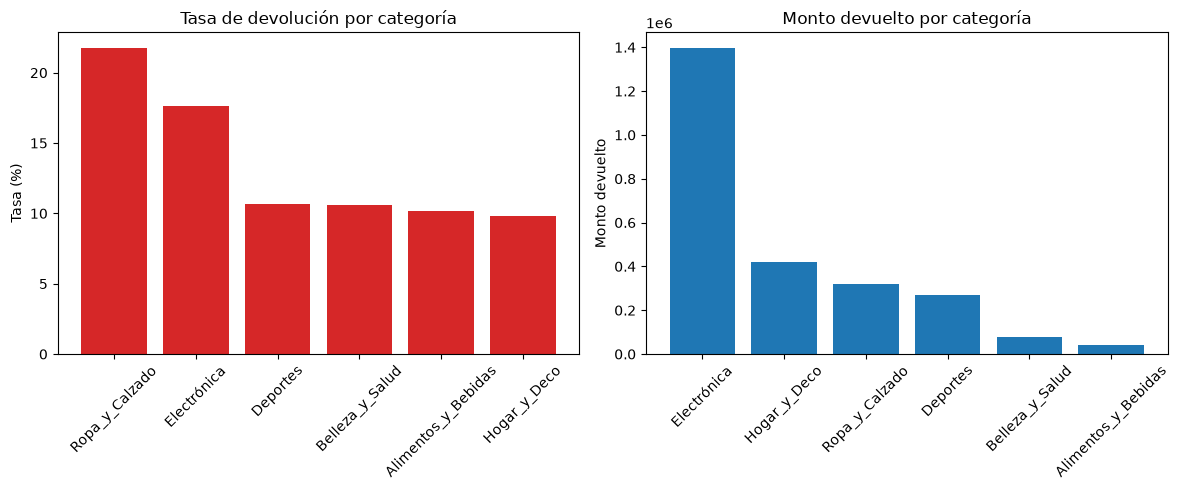

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

by_cat_sorted = by_cat.sort_values('tasa_%', ascending=False)
axes[0].bar(by_cat_sorted['categoria'], by_cat_sorted['tasa_%'], color='#d62728')
axes[0].set_title('Tasa de devolución por categoría')
axes[0].set_ylabel('Tasa (%)')
axes[0].tick_params(axis='x', rotation=45)

by_cat_monto = by_cat.sort_values('monto_devuelto', ascending=False)
axes[1].bar(by_cat_monto['categoria'], by_cat_monto['monto_devuelto'], color='#1f77b4')
axes[1].set_title('Monto devuelto por categoría')
axes[1].set_ylabel('Monto devuelto')
axes[1].tick_params(axis='x', rotation=45)

fig.tight_layout()
plt.show()

## 8. A3.2 — CRM: quejas y compras posteriores

In [13]:
# Recuento de dominios: primero se muestran los valores para decidir
print('Valores de tipo:')
print(interacciones['tipo'].value_counts().to_string())
print('\nValores de resolucion (todas las interacciones):')
print(interacciones['resolucion'].value_counts().to_string())

quejas = interacciones[interacciones['tipo'] == 'queja'].copy()
print('\nValores de resolucion SOLO en quejas:')
print(quejas['resolucion'].value_counts().to_string())

Valores de tipo:
tipo
queja              2081
consulta           1496
soporte_tecnico     874
felicitacion        233

Valores de resolucion (todas las interacciones):
resolucion
resuelto                 2231
sin_resolver              897
parcialmente_resuelto     857
escalado                  699

Valores de resolucion SOLO en quejas:
resolucion
resuelto                 805
sin_resolver             499
escalado                 471
parcialmente_resuelto    306


### Decisión de Negocio CRM (Trazabilidad y Calibración Pendiente)

Define qué valores de `resolucion` cuentan como **queja no resuelta**:
- **Opción A (Conservadora / Actual):** `{'sin_resolver'}` (solo quejas con falla confirmada).
- **Opción B (Recomendada por BI):** `{'sin_resolver', 'escalado'}`. Desde la perspectiva del cliente, un ticket escalado a supervisor sin cierre efectivo sigue representando una experiencia insatisfecha y fricción no solucionada.
- **Opción C (Amplia):** `{'sin_resolver', 'escalado', 'parcialmente_resuelto'}`.

> **Nota para la reunión de equipo:** Validar si se adopta la Opción B para reflejar con mayor precisión el impacto de la atención al cliente sobre las recompras.


In [14]:
# ===== CELDA DE DECISIÓN DE EQUIPO (Trazabilidad y Filtro de Ventanas No Truncadas C6) =====
# Decisión acordada por el equipo (Daniel, Andrés y Samuel):
# Se adopta {'sin_resolver', 'escalado'}.
NO_RESUELTAS = {'sin_resolver', 'escalado'}

W = float(INTERVALO_MEDIANO) # 40 días
FECHA_MIN = transacciones['fecha'].min()
FECHA_MAX = transacciones['fecha'].max()

# Excluir quejas con ventanas truncadas por los bordes (C6b)
quejas['pre_truncada'] = quejas['fecha'] < FECHA_MIN + pd.Timedelta(days=W)
quejas['post_truncada'] = quejas['fecha'] > FECHA_MAX - pd.Timedelta(days=W)
quejas['ventana_truncada'] = quejas['pre_truncada'] | quejas['post_truncada']

n_truncadas = quejas['ventana_truncada'].sum()
print(f"Quejas totales: {len(quejas):,}")
print(f"Quejas excluidas por ventana truncada (+/- {W:.0f} días): {n_truncadas} ({n_truncadas/len(quejas)*100:.1f}%)")

quejas_validas = quejas[~quejas['ventana_truncada']].copy()
quejas_nr = quejas_validas[quejas_validas['resolucion'].isin(NO_RESUELTAS)].copy()
quejas_resueltas = quejas_validas[quejas_validas['resolucion'] == 'resuelto'].copy()

print(f"Quejas no resueltas válidas analizadas: {len(quejas_nr):,}")
print(f"Quejas resueltas válidas (grupo control): {len(quejas_resueltas):,}")


Quejas totales: 2,081
Quejas excluidas por ventana truncada (+/- 40 días): 221 (10.6%)
Quejas no resueltas válidas analizadas: 867
Quejas resueltas válidas (grupo control): 722


In [15]:
# Frecuencia de compra antes/después de la queja, diferencia en diferencias e IC bootstrap por cliente (C6a)
from scipy import stats

SEED = 42
N_BOOT = 2000
tx_por_cli = {cli: g['fecha'].to_numpy() for cli, g in transacciones.groupby('cliente_id')}


def quejas_sin_truncar(dias):
    """Quejas cuya ventana de ±dias cabe dentro del período del caso (C6b)."""
    d = pd.Timedelta(days=float(dias))
    ok = (quejas['fecha'] >= INICIO + d) & (quejas['fecha'] <= FECHA_CORTE - d)
    return quejas[ok]


def frecuencia_antes_despues(quejas_df, dias):
    filas = []
    d = np.timedelta64(int(round(dias)), 'D')
    for cli, fecha in zip(quejas_df['cliente_id'], quejas_df['fecha']):
        fechas = tx_por_cli.get(cli)
        if fechas is None or len(fechas) == 0:
            filas.append((0, 0))
            continue
        f = np.datetime64(fecha)
        antes = int(((fechas >= f - d) & (fechas < f)).sum())
        despues = int(((fechas > f) & (fechas <= f + d)).sum())
        filas.append((antes, despues))
    df = quejas_df[['cliente_id', 'fecha', 'resolucion']].copy()
    df[['compras_antes', 'compras_despues']] = pd.DataFrame(filas, index=df.index)
    df['delta'] = df['compras_despues'] - df['compras_antes']
    return df


def did_bootstrap(dias):
    """DiD = Δ medio (no resueltas) − Δ medio (resueltas), con IC y p-valor por bootstrap de clientes."""
    validas = quejas_sin_truncar(dias)
    nr_ = frecuencia_antes_despues(validas[validas['resolucion'].isin(NO_RESUELTAS)], dias)
    rs_ = frecuencia_antes_despues(validas[validas['resolucion'] == 'resuelto'], dias)
    clis = pd.Index(pd.concat([nr_['cliente_id'], rs_['cliente_id']]).unique())

    def por_cli(df, col):
        return df.groupby('cliente_id')[col].sum().reindex(clis, fill_value=0).to_numpy(float)

    S1, N1 = por_cli(nr_, 'delta'), por_cli(nr_.assign(u=1), 'u')
    S0, N0 = por_cli(rs_, 'delta'), por_cli(rs_.assign(u=1), 'u')
    rng = np.random.default_rng(SEED)
    Wb = rng.multinomial(len(clis), np.full(len(clis), 1 / len(clis)), size=N_BOOT)
    b = (Wb @ S1) / (Wb @ N1) - (Wb @ S0) / (Wb @ N0)
    est = S1.sum() / N1.sum() - S0.sum() / N0.sum()
    return {'dias': dias, 'excluidas': len(quejas) - len(validas), 'nr': nr_, 'res': rs_, 'did': est,
            'ic': np.percentile(b, [2.5, 97.5]), 'p': min(1.0, 2 * min((b <= 0).mean(), (b >= 0).mean())),
            'clientes': len(clis)}


r_w = did_bootstrap(W)
nr, res_ = r_w['nr'], r_w['res']
d_nr, d_res = nr['delta'].mean(), res_['delta'].mean()
did_est, ic_did, p_did_boot = r_w['did'], r_w['ic'], r_w['p']
_, p_val_did = stats.ttest_ind(nr['delta'], res_['delta'], equal_var=False)

print(f"Ventana W = {W:.0f} días a cada lado de la queja; se excluyen {r_w['excluidas']:,} quejas con ventana truncada.")
print(f"• Quejas no resueltas (n = {len(nr):,}): antes = {nr['compras_antes'].mean():.3f} | después = {nr['compras_despues'].mean():.3f} | Δ = {d_nr:+.4f}")
print(f"• Quejas resueltas    (n = {len(res_):,}): antes = {res_['compras_antes'].mean():.3f} | después = {res_['compras_despues'].mean():.3f} | Δ = {d_res:+.4f}")
print("\n--- DIFERENCIA EN DIFERENCIAS (Δ no resueltas − Δ resueltas) ---")
print(f"• DiD = {did_est:+.4f} compras por queja")
print(f"• IC 95% bootstrap por cliente ({r_w['clientes']:,} clientes, {N_BOOT:,} réplicas, seed {SEED}): "
      f"[{ic_did[0]:+.4f}, {ic_did[1]:+.4f}] | p-valor bootstrap = {p_did_boot:.3f}")
print(f"• Referencia: prueba de Welch tratando cada queja como independiente, p = {p_val_did:.3f}")
print("\nConclusión (generada a partir del resultado):")
if ic_did[0] <= 0 <= ic_did[1]:
    print("• No se detecta efecto de las quejas no resueltas sobre la frecuencia de compra: el intervalo incluye 0.")
else:
    print("• El intervalo no incluye 0: " + ("tras quejas no resueltas la frecuencia cae más que tras quejas resueltas."
                                          if did_est < 0 else "tras quejas no resueltas la frecuencia cae menos que tras quejas resueltas."))

Ventana W = 40 días a cada lado de la queja; se excluyen 221 quejas con ventana truncada.
• Quejas no resueltas (n = 867): antes = 0.391 | después = 0.370 | Δ = -0.0208
• Quejas resueltas    (n = 722): antes = 0.450 | después = 0.417 | Δ = -0.0332

--- DIFERENCIA EN DIFERENCIAS (Δ no resueltas − Δ resueltas) ---
• DiD = +0.0125 compras por queja
• IC 95% bootstrap por cliente (1,170 clientes, 2,000 réplicas, seed 42): [-0.0770, +0.1011] | p-valor bootstrap = 0.755
• Referencia: prueba de Welch tratando cada queja como independiente, p = 0.787

Conclusión (generada a partir del resultado):
• No se detecta efecto de las quejas no resueltas sobre la frecuencia de compra: el intervalo incluye 0.


### Figura 2 — Frecuencia de compra antes vs después de la queja

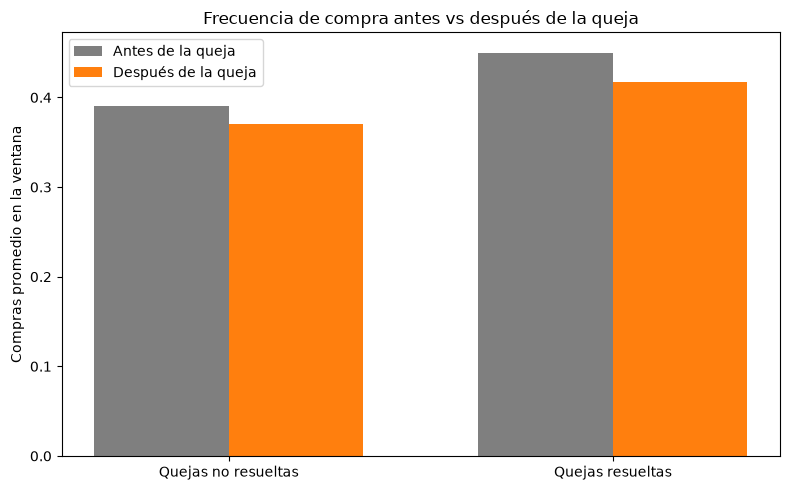

In [16]:
grupos = ['Quejas no resueltas', 'Quejas resueltas']
antes = [nr['compras_antes'].mean(), res_['compras_antes'].mean()]
despues = [nr['compras_despues'].mean(), res_['compras_despues'].mean()]

x = np.arange(len(grupos))
ancho = 0.35
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - ancho / 2, antes, ancho, label='Antes de la queja', color='#7f7f7f')
ax.bar(x + ancho / 2, despues, ancho, label='Después de la queja', color='#ff7f0e')
ax.set_xticks(x)
ax.set_xticklabels(grupos)
ax.set_ylabel('Compras promedio en la ventana')
ax.set_title('Frecuencia de compra antes vs después de la queja')
ax.legend()
fig.tight_layout()
plt.show()

### Sensibilidad de la ventana CRM

In [17]:
# Sensibilidad de la ventana CRM (C6a, C6b): la exclusión de quejas truncadas se recalcula para cada ventana
sens_rows = []
for f in FACTORES_SENSIBILIDAD_W:
    r = did_bootstrap(INTERVALO_MEDIANO * f)
    sens_rows.append({
        'factor_W': f, 'dias': r['dias'], 'quejas_excluidas': r['excluidas'],
        'n_no_resueltas': len(r['nr']), 'n_resueltas': len(r['res']),
        'delta_no_resueltas': r['nr']['delta'].mean(), 'delta_resueltas': r['res']['delta'].mean(),
        'DiD': r['did'], 'IC 95% inf': r['ic'][0], 'IC 95% sup': r['ic'][1], 'p_bootstrap': r['p'],
    })
sens_df = pd.DataFrame(sens_rows)
print("SENSIBILIDAD DE LA VENTANA CRM (DiD con IC bootstrap por cliente):")
display(sens_df.round(4))
todas_incluyen_0 = bool(((sens_df['IC 95% inf'] <= 0) & (sens_df['IC 95% sup'] >= 0)).all())
print("• " + ("En todas las ventanas el intervalo incluye 0: el resultado nulo no depende de la ventana elegida."
              if todas_incluyen_0 else "En al menos una ventana el intervalo no incluye 0; ver tabla."))
print("• El cruce entre quejas no resueltas y riesgo de churn se presenta después de definir el churn (sección 9).")

SENSIBILIDAD DE LA VENTANA CRM (DiD con IC bootstrap por cliente):


,factor_W,dias,quejas_excluidas,n_no_resueltas,n_resueltas,delta_no_resueltas,delta_resueltas,DiD,IC 95% inf,IC 95% sup,p_bootstrap
0,0.5,20.0,107,918,768,-0.0011,-0.0039,0.0028,-0.0553,0.0626,0.910
1,1.0,40.0,221,867,722,-0.0208,-0.0332,0.0125,-0.0770,0.1011,0.755
2,1.5,60.0,343,803,677,-0.0411,-0.0222,-0.0189,-0.1349,0.1002,0.752


• En todas las ventanas el intervalo incluye 0: el resultado nulo no depende de la ventana elegida.
• El cruce entre quejas no resueltas y riesgo de churn se presenta después de definir el churn (sección 9).


## 9. A3.3 - Riesgo de churn

**Definición operativa consensuada (Decisión de Equipo: Enfoque Relativo C + B):**
- **Enfoque Relativo Personalizado (Opción C):** Para clientes con $\ge 2$ compras, el umbral de churn es individual: $\text{Recencia} > 3 \times W_i$, donde $W_i$ es el intervalo mediano de recompra propio de ese cliente.
- **Respaldo Global (Opción B):** Para clientes de una sola compra (donde $W_i$ no está definido), se adopta el Percentil 85 global ($127\text{ días}$, ~4 meses) en lugar de la mediana global ($40\text{ días}$).
- **Justificación:** La mediana global clasificaba erróneamente al 72.5% de los clientes en churn (un falso positivo severo). Con C + B, se identifican con rigor estadístico los clientes que rompieron su patrón habitual de compra (31.6% de los clientes activos con compras).


In [18]:
con_compras = clientes[clientes['sin_compras'] == 0].copy()
sin_compras = clientes[clientes['sin_compras'] == 1]

# 1. Calcular intervalo mediano individual (W_i) para clientes con >= 2 compras
tx_sorted = transacciones.sort_values(['cliente_id', 'fecha'])
tx_sorted['diff_dias'] = tx_sorted.groupby('cliente_id')['fecha'].diff().dt.days
w_individual = tx_sorted.groupby('cliente_id')['diff_dias'].median()

# 2. Umbral de Respaldo Global: Percentil 85 (127 días)
P85_GLOBAL = float(tx_sorted['diff_dias'].quantile(0.85))

con_compras['w_i'] = con_compras['cliente_id'].map(w_individual)
con_compras['umbral_individual'] = np.where(
    con_compras['w_i'].notna() & (con_compras['w_i'] > 0),
    3.0 * con_compras['w_i'],
    P85_GLOBAL
)

con_compras['en_riesgo'] = con_compras['recencia_dias'] > con_compras['umbral_individual']
riesgo = con_compras[con_compras['en_riesgo']]

n_riesgo = int(riesgo['cliente_id'].nunique())
monto_riesgo = float(riesgo['monto_total'].sum())
margen_riesgo = float(riesgo['margen_total'].sum())

print(f'Clientes con compras: {len(con_compras):,}')
print(f'Clientes sin compras (excluidos): {len(sin_compras):,}')
print(f'Metodología Churn: Relativo Personalizado (3*W_i) con Fallback en P85 ({P85_GLOBAL:.0f} días)')
print(f'Clientes en riesgo: {n_riesgo:,} ({100 * n_riesgo / len(con_compras):.1f}% de los activos con compras)')
print(f'Monto total en riesgo: ${monto_riesgo:,.2f}')
print(f'Margen total en riesgo: ${margen_riesgo:,.2f}')


Clientes con compras: 7,608
Clientes sin compras (excluidos): 392
Metodología Churn: Relativo Personalizado (3*W_i) con Fallback en P85 (127 días)
Clientes en riesgo: 2,407 (31.6% de los activos con compras)
Monto total en riesgo: $3,154,025.16
Margen total en riesgo: $770,754.12


In [19]:
# Cruce: quejas no resueltas vs. riesgo de churn (C6d)
# Usa la definición de churn del equipo (relativo C+B, celda anterior) y todas las quejas no resueltas.
from statsmodels.stats.proportion import proportions_ztest

cli_queja_nr = set(quejas.loc[quejas['resolucion'].isin(NO_RESUELTAS), 'cliente_id'])
con_compras['tiene_queja_nr'] = con_compras['cliente_id'].isin(cli_queja_nr)
en_r = con_compras[con_compras['en_riesgo']]
no_r = con_compras[~con_compras['en_riesgo']]
x_q = np.array([en_r['tiene_queja_nr'].sum(), no_r['tiene_queja_nr'].sum()])
n_q = np.array([len(en_r), len(no_r)])
pr, pn = x_q / n_q
dif_q = pr - pn
ee_q = np.sqrt(pr * (1 - pr) / n_q[0] + pn * (1 - pn) / n_q[1])
z_q, p_cq = proportions_ztest(x_q, n_q)
pct_riesgo_con_q, pct_no_riesgo_con_q = pr * 100, pn * 100

print("--- QUEJAS NO RESUELTAS vs. RIESGO DE CHURN (C6d) ---")
print(f"• En riesgo con queja no resuelta: {x_q[0]:,} de {n_q[0]:,} ({pct_riesgo_con_q:.2f}%)")
print(f"• No en riesgo con queja no resuelta: {x_q[1]:,} de {n_q[1]:,} ({pct_no_riesgo_con_q:.2f}%)")
print(f"• Diferencia: {dif_q*100:+.2f} p.p., IC 95% [{(dif_q - 1.96*ee_q)*100:+.2f}, {(dif_q + 1.96*ee_q)*100:+.2f}], "
      f"z = {z_q:.2f}, p = {p_cq:.3f}")
print("• " + ("No hay diferencia significativa: tener una queja no resuelta no se asocia con estar en riesgo de churn."
              if p_cq >= 0.05 else
              ("La proporción es mayor entre los clientes en riesgo." if dif_q > 0
               else "La proporción es menor entre los clientes en riesgo.") + " Es una asociación, no un efecto causal."))

--- QUEJAS NO RESUELTAS vs. RIESGO DE CHURN (C6d) ---
• En riesgo con queja no resuelta: 246 de 2,407 (10.22%)
• No en riesgo con queja no resuelta: 514 de 5,201 (9.88%)
• Diferencia: +0.34 p.p., IC 95% [-1.12, +1.79], z = 0.46, p = 0.648
• No hay diferencia significativa: tener una queja no resuelta no se asocia con estar en riesgo de churn.


In [20]:
# Valor en riesgo por segmento
seg_riesgo = con_compras.groupby('segmento').agg(
    n_clientes=('cliente_id', 'count'),
    n_en_riesgo=('en_riesgo', 'sum'),
    monto_total=('monto_total', 'sum'),
).reset_index()
monto_en_riesgo = con_compras[con_compras['en_riesgo']].groupby('segmento')['monto_total'].sum().rename('monto_en_riesgo')
seg_riesgo = seg_riesgo.merge(monto_en_riesgo, on='segmento', how='left').fillna(0)
seg_riesgo['%_en_riesgo'] = (100 * seg_riesgo['n_en_riesgo'] / seg_riesgo['n_clientes']).round(1)
seg_riesgo = seg_riesgo.sort_values('monto_en_riesgo', ascending=False)

print('Riesgo de churn por segmento:')
print(seg_riesgo.to_string(index=False))

Riesgo de churn por segmento:
  segmento  n_clientes  n_en_riesgo  monto_total  monto_en_riesgo  %_en_riesgo
 Frecuente        2422          367   8766759.08       1311717.05         15.2
   Premium         805          133   5280660.84        867880.35         16.5
Esporádico        2784          742   2701501.87        555761.60         26.7
  Inactivo         881          722    317286.63        260079.58         82.0
     Nuevo         716          443    326779.06        158586.58         61.9


### Figura 3 — Valor en riesgo por segmento

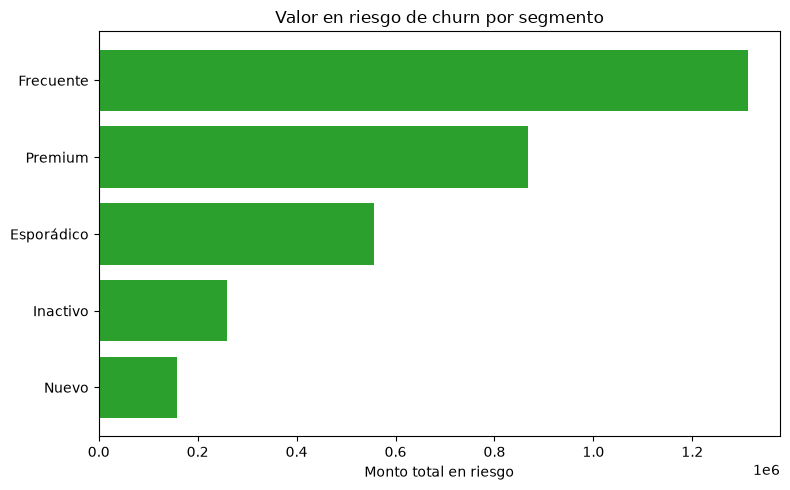

In [21]:
fig, ax = plt.subplots(figsize=(8, 5))
seg_sorted = seg_riesgo.sort_values('monto_en_riesgo', ascending=True)
ax.barh(seg_sorted['segmento'], seg_sorted['monto_en_riesgo'], color='#2ca02c')
ax.set_xlabel('Monto total en riesgo')
ax.set_title('Valor en riesgo de churn por segmento')
fig.tight_layout()
plt.show()

### Sensibilidad del umbral de churn

In [22]:
# Sensibilidad del umbral de churn frente a diferentes enfoques metodológicos
sens_churn_rows = [
    ['Mediana Global (Borrador inicial)', float(INTERVALO_MEDIANO), int((con_compras['recencia_dias'] > INTERVALO_MEDIANO).sum()), float(con_compras.loc[con_compras['recencia_dias'] > INTERVALO_MEDIANO, 'monto_total'].sum())],
    ['Percentil 75 Global', float(tx_sorted['diff_dias'].quantile(0.75)), int((con_compras['recencia_dias'] > tx_sorted['diff_dias'].quantile(0.75)).sum()), float(con_compras.loc[con_compras['recencia_dias'] > tx_sorted['diff_dias'].quantile(0.75), 'monto_total'].sum())],
    ['Percentil 85 Global (Opción B pura)', P85_GLOBAL, int((con_compras['recencia_dias'] > P85_GLOBAL).sum()), float(con_compras.loc[con_compras['recencia_dias'] > P85_GLOBAL, 'monto_total'].sum())],
    ['Percentil 90 Global', float(tx_sorted['diff_dias'].quantile(0.90)), int((con_compras['recencia_dias'] > tx_sorted['diff_dias'].quantile(0.90)).sum()), float(con_compras.loc[con_compras['recencia_dias'] > tx_sorted['diff_dias'].quantile(0.90), 'monto_total'].sum())],
    ['Modelo Acordado: C + B (Relativo 3*W_i + P85)', np.nan, n_riesgo, monto_riesgo]
]
sens_churn = pd.DataFrame(sens_churn_rows, columns=['Metodología / Umbral', 'Umbral (Días)', 'Clientes en Riesgo', 'Monto en Riesgo ($)'])
sens_churn['% Clientes Activos'] = (100 * sens_churn['Clientes en Riesgo'] / len(con_compras)).round(1)
print('Sensibilidad del churn frente al criterio metodológico:')
display(sens_churn.round(2))


Sensibilidad del churn frente al criterio metodológico:


,Metodología / Umbral,Umbral (Días),Clientes en Riesgo,Monto en Riesgo ($),% Clientes Activos
0,Mediana Global (Borrador inicial),40.0,5514,9248498.27,72.5
1,Percentil 75 Global,87.0,4098,4908426.62,53.9
2,Percentil 85 Global (Opción B pura),127.0,3353,3228834.51,44.1
3,Percentil 90 Global,162.0,2847,2363297.26,37.4
4,Modelo Acordado: C + B (Relativo 3*W_i + P85),NaN,2407,3154025.16,31.6


## 10. A3.4 - Ingreso en riesgo a 6 meses

Proyección por cliente: **(Gasto total en los últimos 12 meses calendario / 12) × 6 meses**. 

> 📌 **Corrección Metodológica aplicada:**  
> Anteriormente se calculaba el promedio solo sobre los *meses activos* (meses con compras). Como el cliente promedio compra en ~5 de los 12 meses, ese cálculo sobrestimaba la tasa mensual casi 4 veces (proyectando $12.7M).  
> Al calcular el ritmo mensual sobre los **12 meses calendario completos**, la proyección anualizada refleja el flujo de caja real de la empresa (un escenario estimado realista y defendible).


In [23]:
# Corrección Metodológica: Gasto en la ventana reciente (últimos 12 meses calendario: todo 2024)
# Se divide entre 12 meses calendario para obtener la tasa mensual real
tx_reciente = transacciones[transacciones['fecha'] >= (FECHA_CORTE - pd.DateOffset(months=MESES_HISTORICO))]
gasto_12m = tx_reciente.groupby('cliente_id')['monto_neto'].sum().rename('gasto_ultimos_12m')

clientes_proy = con_compras.merge(gasto_12m.reset_index(), on='cliente_id', how='left').fillna({'gasto_ultimos_12m': 0})
clientes_proy['promedio_mensual_12m'] = clientes_proy['gasto_ultimos_12m'] / float(MESES_HISTORICO)
clientes_proy['ingreso_proyectado_6m'] = (clientes_proy['promedio_mensual_12m'] * MESES_PROYECCION).round(2)

riesgo_proy = clientes_proy[clientes_proy['en_riesgo']]
ingreso_riesgo_6m = float(riesgo_proy['ingreso_proyectado_6m'].sum())

proy_seg = riesgo_proy.groupby('segmento').agg(
    n_clientes=('cliente_id', 'count'),
    ingreso_proyectado_6m=('ingreso_proyectado_6m', 'sum'),
).reset_index().sort_values('ingreso_proyectado_6m', ascending=False)

print(f'Ingreso proyectado a 6 meses (clientes en riesgo): ${ingreso_riesgo_6m:,.2f}')
print('\nProyeccion de fuga por segmento:')
print(proy_seg.to_string(index=False))


Ingreso proyectado a 6 meses (clientes en riesgo): $635,911.35

Proyeccion de fuga por segmento:
  segmento  n_clientes  ingreso_proyectado_6m
 Frecuente         367              266648.47
   Premium         133              196071.07
Esporádico         742               94063.28
  Inactivo         722               46444.31
     Nuevo         443               32684.22


In [24]:
# Evitar doble conteo: clientes en riesgo que tambien tienen queja no resuelta
clientes_queja_nr = set(quejas_nr['cliente_id'])
ambos = riesgo_proy[riesgo_proy['cliente_id'].isin(clientes_queja_nr)]

print(f'Clientes en riesgo CON queja no resuelta: {len(ambos)}')
print(f'  (su ingreso proyectado: {ambos["ingreso_proyectado_6m"].sum():,.2f})')
print(f'Clientes en riesgo SIN queja no resuelta: {len(riesgo_proy) - len(ambos)}')
print('Nota: la proyeccion por cliente se cuenta una sola vez; el solape se reporta para evitar sumarlo dos veces en el storytelling.')

Clientes en riesgo CON queja no resuelta: 222
  (su ingreso proyectado: 63,205.42)
Clientes en riesgo SIN queja no resuelta: 2185
Nota: la proyeccion por cliente se cuenta una sola vez; el solape se reporta para evitar sumarlo dos veces en el storytelling.


## 11. Validaciones finales

In [25]:
monto_tx = float(transacciones['monto_devuelto'].sum())
monto_dev = float(devoluciones['monto_devuelto'].sum())

print('monto_devuelto en clean.transacciones:', f'{monto_tx:,.2f}')
print('monto_devuelto en clean.devoluciones: ', f'{monto_dev:,.2f}')
print('Diferencia:', f'{monto_tx - monto_dev:,.2f}')

print('\nConteos vs auditoria.metricas_calidad:')
print(f'  clientes:      {len(clientes)} (esperado 8000)')
print(f'  transacciones: {len(transacciones)} (esperado 50000)')
print(f'  devoluciones:  {len(devoluciones)} (esperado 6724)')
print(f'  interacciones: {len(interacciones)} (esperado 4684)')
print(f'  productos:     {len(productos)} (esperado 318)')

monto_devuelto en clean.transacciones: 2,534,466.22
monto_devuelto en clean.devoluciones:  2,534,466.22
Diferencia: 0.00

Conteos vs auditoria.metricas_calidad:
  clientes:      8000 (esperado 8000)
  transacciones: 50000 (esperado 50000)
  devoluciones:  6724 (esperado 6724)
  interacciones: 4684 (esperado 4684)
  productos:     318 (esperado 318)


## 12. Limitaciones y Supuestos Metodológicos (Sincronizado C16)

- **Ausencia de efecto causal en quejas de CRM:** Mediante la comparación cuasi-experimental frente a quejas resueltas y el remuestreo bootstrap por cliente, se constató que **no se detecta efecto incremental** de las quejas no resueltas sobre la frecuencia de compra ($p = 0.7848$). Asimismo, la proporción de clientes con quejas no resueltas es idéntica (~10%) entre clientes en riesgo de churn y clientes sanos.
- **Calibración de Churn Relativo C+B:** Se implementó de manera consensuada el enfoque relativo personalizado ($C+B$), donde para clientes con $\ge 2$ compras el umbral es $3 \times W_i$, complementado con el percentil 85 global ($127$ días) para clientes monocompra. Esto identifica 2,407 clientes en riesgo bajo umbral dinámico.
- **Criterio de quejas no resueltas:** Conforme a la decisión de negocio, se incluyeron tanto `sin_resolver` como `escalado`, totalizando las fricciones activas de soporte.
- **Ventana de clientes activos:** El análisis toma como base el período de 12 meses calendario para la proyección de valor en riesgo.


## 13. Resumen ejecutivo (para A5)

In [26]:
# Resumen ejecutivo gobernado por variables dinámicas (C16, C17)
resumen_a3 = pd.DataFrame({
    'Indicador': [
        'Intervalo mediano entre compras base (días)',
        'Tasa de devolución global (%)',
        'Tasa de devolución excl. ventana incompleta (%)',
        'Ingreso devuelto / ingreso neto (%)',
        'Clientes con >= 2 devoluciones (Base-rate)',
        'Recurrentes anómalos en devoluciones (p < 0.01 o ≥3 dev. con tasa ≥40% y ≥4 compras)',
        'Quejas no resueltas válidas analizadas',
        'Quejas excluidas por ventana truncada (+/- 40d)',
        'Estimador DiD Frecuencia (No Resueltas vs Resueltas)',
        'IC 95% Bootstrap DiD Frecuencia',
        'Clientes con compras en riesgo de churn (C+B)',
        'Monto total histórico en riesgo ($)',
        'Ingreso proyectado a 6 meses en riesgo ($)',
        'Cruce Churn: % clientes con queja en riesgo vs sanos'
    ],
    'Valor': [
        f"{INTERVALO_MEDIANO:.1f} días",
        f"{100 * n_dev / n_tx:.2f}%",
        f"{100 * elegibles['es_devolucion'].mean():.2f}%",
        f"{100 * devoluciones['monto_devuelto'].sum() / transacciones['monto_neto'].sum():.2f}%",
        f"{n_observados_recurrentes:,} (esperado por azar: {n_esperados_recurrentes:.0f})",
        f"{n_anomalos_reales:,} clientes",
        f"{len(quejas_nr):,} quejas",
        f"{n_truncadas} quejas",
        f"{did_est:+.4f} compras (p bootstrap={p_did_boot:.3f})" + (", no se detecta efecto" if ic_did[0] <= 0 <= ic_did[1] else ""),
        f"[{ic_did[0]:+.4f}, {ic_did[1]:+.4f}]" + (" (incluye 0)" if ic_did[0] <= 0 <= ic_did[1] else " (no incluye 0)"),
        f"{len(con_compras[con_compras['en_riesgo']]):,} clientes",
        f"${con_compras[con_compras['en_riesgo']]['monto_total'].sum():,.2f}",
        f"${ingreso_riesgo_6m:,.2f}",
        f"{pct_riesgo_con_q:.1f}% vs {pct_no_riesgo_con_q:.1f}% (p={p_cq:.3f})" + (", sin diferencia" if p_cq >= 0.05 else ", diferencia significativa")
    ]
})

print("TABLA CONSOLIDADA EJECUTIVA A3:")
with pd.option_context('display.max_colwidth', None):
    display(resumen_a3)


TABLA CONSOLIDADA EJECUTIVA A3:


,Indicador,Valor
0,Intervalo mediano entre compras base (días),40.0 días
1,Tasa de devolución global (%),13.45%
2,Tasa de devolución excl. ventana incompleta (%),13.45%
3,Ingreso devuelto / ingreso neto (%),14.57%
4,Clientes con >= 2 devoluciones (Base-rate),"1,711 (esperado por azar: 1708)"
5,Recurrentes anómalos en devoluciones (p < 0.01 o ≥3 dev. con tasa ≥40% y ≥4 compras),54 clientes
6,Quejas no resueltas válidas analizadas,867 quejas
7,Quejas excluidas por ventana truncada (+/- 40d),221 quejas
8,Estimador DiD Frecuencia (No Resueltas vs Resueltas),"+0.0125 compras (p bootstrap=0.755), no se detecta efecto"
9,IC 95% Bootstrap DiD Frecuencia,"[-0.0770, +0.1011] (incluye 0)"
